# PageRank as a Large Sparse Eigenvalue Problem
**Computational Linear Algebra for Large Scale Problems, HW1 (Project 4)**

**Research question:** How do graph structure and the damping parameter
determine the convergence and stability of PageRank?

**Notebook structure**
1. Environment
2. Small 4-node graph and dense reference solution
3. Sparse transition matrix with implicit dangling-node correction
4. Power iteration (core algorithm)
5. Verification tests
6. Test graphs: rank sink, communities, real data
7. Experiments
8. Summary

Run with **Kernel > Restart & Run All**. The two real datasets are downloaded into `data/` on the first run.

## 1. Environment
Imports, folders, random seed and software versions. BLAS is limited to one thread,
so that timings compare algorithms and not the number of CPU cores.

In [1]:
import os
import sys
import time
import platform
import tracemalloc
import urllib.request

import numpy as np
import scipy
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import scipy.stats
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

# One BLAS thread, so that timings compare algorithms and not the number of CPU cores
threadpool_limits(limits=1);

In [2]:
DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Every experiment that needs randomness creates its own generator from SEED
SEED = 42

np.set_printoptions(precision=6, suppress=True, linewidth=120)

print("Python     :", sys.version.split()[0])
print("NumPy      :", np.__version__)
print("SciPy      :", scipy.__version__)
print("NetworkX   :", nx.__version__)
print("Matplotlib :", matplotlib.__version__)
print("OS         :", platform.platform())
print("Seed       :", SEED)

Python     : 3.10.7
NumPy      : 2.2.6
SciPy      : 1.15.3
NetworkX   : 3.4.2
Matplotlib : 3.10.9
OS         : macOS-13.7.8-x86_64-i386-64bit
Seed       : 42


In [3]:
# Helper: save every figure as PDF (report) and PNG (slides)
def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200, bbox_inches="tight")

## 2. Small test graph and dense reference solution

Graph with 4 nodes and edges $0\to1,\ 0\to2,\ 1\to2,\ 2\to0,\ 2\to3$. Node 3 has no out-links (dangling).

**Convention (column-stochastic):** $P_{ij} = 1/\text{outdeg}(j)$ if there is an edge $j \to i$, else $0$.
Column $j$ holds the probabilities of leaving node $j$, so every non-dangling column sums to 1.

**Dangling fix:** with $d_j = 1$ if node $j$ is dangling, $\bar P = P + v\,d^T$ (zero columns replaced by $v$).

**Google matrix:** $G = \alpha \bar P + (1-\alpha)\, v\, e^T$, with $v = e/n$ and $\alpha = 0.85$.

PageRank is the eigenvector $Gx = x$ with $x > 0$ and $\sum_i x_i = 1$.
Here $n = 4$, so we build $G$ densely and use `numpy.linalg.eig` as a reference. This is only for verification.

**Equivalent linear system:** for $e^T x = 1$, $Gx = \alpha\bar P x + (1-\alpha)v$, so
$Gx = x \iff (I - \alpha\bar P)x = (1-\alpha)v$. Our residual $\|Gx - x\|_1$ equals $\|b - Ax\|_1$
with $A = I - \alpha\bar P$, $b = (1-\alpha)v$.

In [4]:
# Small test graph and its dense transition matrix
n_small = 4
edges_small = [(0, 1), (0, 2), (1, 2), (2, 0), (2, 3)]   # (source, target)

out_degree_small = np.zeros(n_small)
for source, target in edges_small:
    out_degree_small[source] += 1

# Column-stochastic convention: P[i, j] = probability of moving from node j to node i
P_dense = np.zeros((n_small, n_small))
for source, target in edges_small:
    P_dense[target, source] = 1.0 / out_degree_small[source]
print("P =\n", P_dense)

# Orientation check: non-dangling columns sum to 1, the dangling column sums to 0
column_sums = P_dense.sum(axis=0)
assert np.allclose(column_sums[out_degree_small > 0], 1.0)
assert np.all(column_sums[out_degree_small == 0] == 0.0)

P =
 [[0.  0.  0.5 0. ]
 [0.5 0.  0.  0. ]
 [0.5 1.  0.  0. ]
 [0.  0.  0.5 0. ]]


In [5]:
# Dangling fix and Google matrix, built densely (reference only, n = 4)
alpha = 0.85                                         # standard damping value (Brin and Page)
v_small = np.ones(n_small) / n_small                 # uniform teleportation vector
d_small = (out_degree_small == 0).astype(float)      # 1 for dangling nodes, 0 otherwise
e_small = np.ones(n_small)

P_bar_dense = P_dense + np.outer(v_small, d_small)   # replace zero columns by v
G_dense = alpha * P_bar_dense + (1 - alpha) * np.outer(v_small, e_small)
print("G =\n", G_dense)

assert np.allclose(G_dense.sum(axis=0), 1.0)         # column-stochastic
assert np.all(G_dense > 0)                           # strictly positive

G =
 [[0.0375 0.0375 0.4625 0.25  ]
 [0.4625 0.0375 0.0375 0.25  ]
 [0.4625 0.8875 0.0375 0.25  ]
 [0.0375 0.0375 0.4625 0.25  ]]


In [6]:
# Reference PageRank from the dense eigendecomposition
eigvals, eigvecs = np.linalg.eig(G_dense)
k = np.argmin(np.abs(eigvals - 1.0))     # index of the eigenvalue closest to 1
x_ref = np.real(eigvecs[:, k])
x_ref = x_ref / x_ref.sum()              # entries sum to 1 (also fixes the sign)

print("Eigenvalues           :", eigvals)
print("Reference PageRank    :", x_ref)
print("Residual ||Gx - x||_1 :", np.linalg.norm(G_dense @ x_ref - x_ref, 1))
assert np.isclose(eigvals[k], 1.0)
assert np.all(x_ref > 0)

Eigenvalues           : [ 1.     +0.j       -0.31875+0.411504j -0.31875-0.411504j  0.     +0.j      ]
Reference PageRank    : [0.233994 0.186671 0.345341 0.233994]
Residual ||Gx - x||_1 : 8.326672684688674e-16


In [7]:
# The same vector solves the linear system (I - alpha * P_bar) x = (1 - alpha) v
A_dense = np.eye(n_small) - alpha * P_bar_dense
x_linear = np.linalg.solve(A_dense, (1 - alpha) * v_small)
print("Linear-system solution:", x_linear)
assert np.allclose(x_linear, x_ref)

Linear-system solution: [0.233994 0.186671 0.345341 0.233994]


## 3. Sparse transition matrix and implicit Google matrix

$P$ is stored in CSR format (only the nonzeros). $G$ is never formed. We only implement its action on a vector:

$$Gx = \alpha P x + \alpha\, v\,(d^T x) + (1-\alpha)\, v\,(e^T x)$$

where $d^T x$ is the total mass on dangling nodes and $e^T x$ is the total mass of $x$.
Cost per product: one sparse matrix-vector product, $O(\text{nnz}(P))$, plus $O(n)$ vector operations. Memory: $O(\text{nnz} + n)$.

In [8]:
# Sparse column-stochastic transition matrix
def build_transition_matrix(n, edges):
    """Return the sparse transition matrix P (CSR) and a boolean dangling mask.

    P[i, j] = 1 / outdeg(j) if there is an edge j -> i.
    Dangling nodes (outdeg = 0) have a zero column in P.
    """
    # Count the outgoing edges of each node
    out_degree = np.zeros(n)
    for source, target in edges:
        out_degree[source] += 1

    # One nonzero entry per edge: P[target, source] = 1 / outdeg(source)
    rows = []
    cols = []
    values = []
    for source, target in edges:
        rows.append(target)
        cols.append(source)
        values.append(1.0 / out_degree[source])

    P = sp.csr_matrix((values, (rows, cols)), shape=(n, n))
    dangling = (out_degree == 0)
    return P, dangling

In [9]:
# Matrix-free product y = G x
def google_matvec(P, dangling, x, alpha, v):
    """Compute G x = alpha * P x + alpha * v * (d^T x) + (1 - alpha) * v * (e^T x) without forming G."""
    dangling_mass = x[dangling].sum()     # d^T x
    total_mass = x.sum()                  # e^T x
    return alpha * (P @ x) + alpha * dangling_mass * v + (1 - alpha) * total_mass * v

In [10]:
# Verify the sparse construction against the dense reference
P_small, dangling_small = build_transition_matrix(n_small, edges_small)

# Test 1: sparse P equals the dense P of Section 2
assert np.allclose(P_small.toarray(), P_dense)

# Test 2: google_matvec equals G_dense @ x, for a generic vector and for every unit vector
rng = np.random.default_rng(SEED)
x_test = rng.standard_normal(n_small)            # not normalized, has negative entries
y_sparse = google_matvec(P_small, dangling_small, x_test, alpha, v_small)
assert np.allclose(y_sparse, G_dense @ x_test)
for j in range(n_small):
    unit = np.zeros(n_small)
    unit[j] = 1.0
    assert np.allclose(google_matvec(P_small, dangling_small, unit, alpha, v_small), G_dense[:, j])

# Test 3: stochasticity without forming dense rank-one matrices
column_sums_P_bar = P_small.T @ np.ones(n_small) + dangling_small   # dangling columns get v, which sums to 1
assert np.allclose(column_sums_P_bar, 1.0)
assert np.isclose(y_sparse.sum(), x_test.sum())  # e^T G x = e^T x

print("Stored nonzeros:", P_small.nnz)
print("Max difference G x (sparse vs dense):", np.max(np.abs(y_sparse - G_dense @ x_test)))
print("All Section 3 checks passed.")

Stored nonzeros: 5
Max difference G x (sparse vs dense): 1.1102230246251565e-16
All Section 3 checks passed.


## 4. Power iteration (core algorithm)

Start from $x_0 = v$ (or from a given $x_0$, used for the warm start in 7.7) and iterate $x_{k+1} = G x_k / (e^T G x_k)$.
Stop when the residual $r_k = \|G x_k - x_k\|_1$ is below a tolerance and return that same $x_k$,
so the error certificate of Section 5 applies to the returned vector.
Since $G x_k$ is the next iterate, the residual costs no extra matrix-vector product.

**Convergence:** the error decreases roughly like $|\lambda_2(G)|^k$, and $|\lambda_2(G)| \le \alpha$.
**Cost:** one sparse matvec per iteration, $O(\text{nnz} + n)$. **Memory:** a few vectors of length $n$.

In [11]:
# Power iteration with a residual-based stopping rule
def power_iteration(P, dangling, alpha, v, tol=1e-10, max_iter=1000, x0=None):
    """Compute PageRank by power iteration.

    Starts from x0 if given (warm start), otherwise from v.
    Returns the iterate x whose residual ||G x - x||_1 was measured last,
    and the list of residuals. The number of matrix-vector products equals len(residuals).
    """
    if x0 is None:
        x = v.copy()
    else:
        x = x0.copy()
    residuals = []
    for k in range(max_iter):
        x_new = google_matvec(P, dangling, x, alpha, v)
        residual = np.linalg.norm(x_new - x, 1)     # residual of the current x
        residuals.append(residual)
        if residual < tol:
            break                                   # return the same x whose residual we measured
        x = x_new / x_new.sum()                     # renormalize against round-off
    return x, residuals

In [12]:
# Run power iteration on the small graph
x_pi, residuals_pi = power_iteration(P_small, dangling_small, alpha, v_small)

lambda2_abs = np.sort(np.abs(eigvals))[::-1][1]          # |lambda_2| from the dense eigenvalues
avg_rate = (residuals_pi[-1] / residuals_pi[0]) ** (1 / (len(residuals_pi) - 1))
ratios = np.array(residuals_pi[1:]) / np.array(residuals_pi[:-1])

print("Iterations (matvecs)  :", len(residuals_pi))
print("PageRank              :", x_pi)
print("||x_pi - x_ref||_1    :", np.linalg.norm(x_pi - x_ref, 1))
print("Average residual rate :", avg_rate, "  |lambda_2| =", lambda2_abs)
print("Ratios r_k+1 / r_k    :", np.round(ratios, 2))

Iterations (matvecs)  : 35
PageRank              : [0.233994 0.186671 0.345341 0.233994]
||x_pi - x_ref||_1    : 4.011754817234703e-11
Average residual rate : 0.5159303932136786   |lambda_2| = 0.5205165703414253
Ratios r_k+1 / r_k    : [0.71 0.38 0.39 0.81 0.58 0.32 0.68 0.69 0.34 0.48 0.78 0.52 0.32 0.73 0.67 0.32 0.55 0.75 0.47 0.32 0.78 0.66 0.32
 0.59 0.73 0.43 0.32 0.84 0.64 0.32 0.63 0.71 0.39 0.38]


**Observation.** The average residual rate is close to $|\lambda_2| = 0.52$, which predicts about
$\ln(10^{-10})/\ln(0.52) \approx 35$ iterations. The individual ratios oscillate because $\lambda_2$ is complex
($\lambda_{2,3} = -0.319 \pm 0.412i$): the slow error component is rotated by about $128^\circ$ per step.

## 5. Verification

**5.1 Small graph:** compare with the dense reference, check positivity, normalization,
the true residual of the returned vector, the bound $\|x - x^*\|_1 \le \|Gx - x\|_1 / (1-\alpha)$,
and the exact tie between nodes 0 and 3 (identical rows of $G$).

**5.2 Cases with an exact answer:** a directed cycle (by symmetry $x_i = 1/n$)
and $\alpha = 0$ (then $G = v e^T$, so $x = v$ for any $v$).

In [13]:
#Checks on the small graph
tol = 1e-10
true_residual = np.linalg.norm(G_dense @ x_pi - x_pi, 1)   # computed independently with dense G
forward_error = np.linalg.norm(x_pi - x_ref, 1)
error_bound = true_residual / (1 - alpha)

print("True residual ||G x - x||_1 :", true_residual)
print("Forward error ||x - x*||_1  :", forward_error)
print("Bound residual / (1-alpha)  :", error_bound)

assert np.all(x_pi > 0)                    # positivity
assert np.isclose(x_pi.sum(), 1.0)         # normalization
assert true_residual < tol                 # eigenvector residual
assert forward_error <= error_bound        # residual bounds the error
assert np.allclose(x_pi, x_ref)            # agreement with numpy.linalg.eig
assert np.isclose(x_pi[0], x_pi[3])        # exact tie predicted by identical rows of G

print("All Section 5.1 checks passed.")

True residual ||G x - x||_1 : 5.3894999574310987e-11
Forward error ||x - x*||_1  : 4.011754817234703e-11
Bound residual / (1-alpha)  : 3.592999971620732e-10
All Section 5.1 checks passed.


In [14]:
#Cases with an exact answer
# (a) Directed cycle 0 -> 1 -> ... -> 4 -> 0: by symmetry every node has PageRank 1/n
n_cycle = 5
edges_cycle = []
for i in range(n_cycle):
    edges_cycle.append((i, (i + 1) % n_cycle))

P_cycle, dangling_cycle = build_transition_matrix(n_cycle, edges_cycle)
v_cycle = np.ones(n_cycle) / n_cycle
x_cycle, residuals_cycle = power_iteration(P_cycle, dangling_cycle, alpha, v_cycle)
print("Cycle PageRank:", x_cycle)
assert np.allclose(x_cycle, 1 / n_cycle)

# (b) alpha = 0: G = v e^T, so the PageRank equals v for any v
v_custom = np.array([0.1, 0.2, 0.3, 0.4])
x_alpha0, residuals_alpha0 = power_iteration(P_small, dangling_small, 0.0, v_custom)
print("alpha = 0 PageRank:", x_alpha0)
assert np.allclose(x_alpha0, v_custom)

print("All Section 5.2 checks passed.")

Cycle PageRank: [0.2 0.2 0.2 0.2 0.2]
alpha = 0 PageRank: [0.1 0.2 0.3 0.4]
All Section 5.2 checks passed.


## 6. Test graphs
The handbook asks for a graph with a rank sink, a graph with communities and a real sparse graph.

### 6.1 Graph with a rank sink
A rank sink is a closed group of nodes with links into it but no links out of it.
Unlike a dangling node, a sink has out-links, so the dangling fix does not help:
only teleportation lets the random surfer escape. $\bar P$ is reducible, so $|\lambda_2(\bar P)| = 1$ and $|\lambda_2(G)| = \alpha$.

Dangling nodes      : 0
Iterations          : 131
PageRank            : [0.052104 0.037144 0.046573 0.034793 0.051932 0.059142 0.085064 0.087304 0.286997 0.258947]
Share of sink {8, 9}: 0.545943592038463


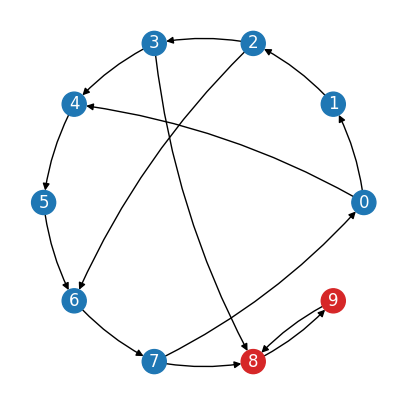

In [15]:
# Graph with a rank sink
def make_rank_sink_graph():
    """10 nodes: a cycle 0..7 with two shortcuts, leaking into the closed pair {8, 9}."""
    n = 10
    edges = []
    for i in range(8):
        edges.append((i, (i + 1) % 8))           # cycle 0 -> 1 -> ... -> 7 -> 0
    edges.append((0, 4))                          # shortcuts inside the cycle
    edges.append((2, 6))
    edges.append((3, 8))                          # links into the sink
    edges.append((7, 8))
    edges.append((8, 9))                          # the sink: 8 and 9 only link to each other
    edges.append((9, 8))
    return n, edges

n_sink, edges_sink = make_rank_sink_graph()
P_sink, dangling_sink = build_transition_matrix(n_sink, edges_sink)
v_sink = np.ones(n_sink) / n_sink
x_sink, residuals_sink = power_iteration(P_sink, dangling_sink, alpha, v_sink)

print("Dangling nodes      :", dangling_sink.sum())
print("Iterations          :", len(residuals_sink))
print("PageRank            :", x_sink)
print("Share of sink {8, 9}:", x_sink[8] + x_sink[9])

# Draw the graph for the report (sink in red, curved edges so that 8 -> 9 and 9 -> 8 are both visible)
graph_sink = nx.DiGraph()
graph_sink.add_edges_from(edges_sink)
colors = []
for node in graph_sink.nodes():
    if node == 8 or node == 9:
        colors.append("tab:red")
    else:
        colors.append("tab:blue")

fig, ax = plt.subplots(figsize=(5, 5))
nx.draw_networkx(graph_sink, pos=nx.circular_layout(graph_sink), ax=ax, node_color=colors,
                 font_color="white", arrows=True, connectionstyle="arc3,rad=0.1")
ax.set_axis_off()
save_fig(fig, "graph_rank_sink")
plt.show()

### 6.2 Graph with communities (stochastic block model)
Nodes are split into blocks; an edge $i \to j$ exists with probability $p_{in}$ inside a block and $p_{out}$ between blocks.
Weak links between blocks make $|\lambda_2(\bar P)|$ close to 1, so convergence slows down as $\alpha \to 1$.

Nodes          : 300
Edges (nnz)    : 3077
Dangling nodes : 0
Iterations     : 84


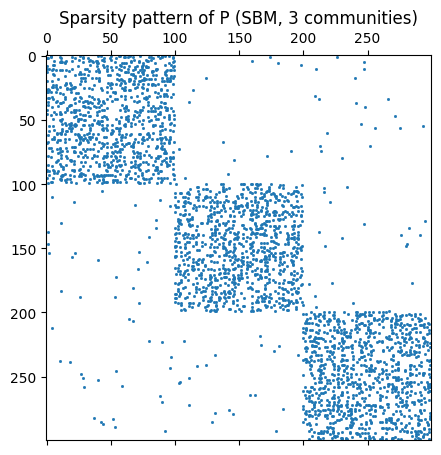

In [16]:
# Graph with communities (stochastic block model)
def make_community_graph(sizes, p_in, p_out, seed):
    """Directed SBM: edge probability p_in inside a block, p_out between blocks."""
    k = len(sizes)
    probs = []
    for a in range(k):
        row = []
        for b in range(k):
            if a == b:
                row.append(p_in)
            else:
                row.append(p_out)
        probs.append(row)

    G_nx = nx.stochastic_block_model(sizes, probs, seed=seed, directed=True)
    n = G_nx.number_of_nodes()
    edges = list(G_nx.edges())
    return n, edges

n_sbm, edges_sbm = make_community_graph([100, 100, 100], p_in=0.1, p_out=0.002, seed=SEED)
P_sbm, dangling_sbm = build_transition_matrix(n_sbm, edges_sbm)
v_sbm = np.ones(n_sbm) / n_sbm
x_sbm, residuals_sbm = power_iteration(P_sbm, dangling_sbm, alpha, v_sbm)

print("Nodes          :", n_sbm)
print("Edges (nnz)    :", P_sbm.nnz)
print("Dangling nodes :", dangling_sbm.sum())
print("Iterations     :", len(residuals_sbm))

# Sparsity pattern of P: the three communities appear as diagonal blocks
fig, ax = plt.subplots(figsize=(5, 5))
ax.spy(P_sbm, markersize=1)
ax.set_title("Sparsity pattern of P (SBM, 3 communities)")
save_fig(fig, "sbm_sparsity_pattern")
plt.show()

### 6.3 Real graphs (SNAP)
- **wiki-Vote** (7,115 nodes, 103,689 edges): Wikipedia administrator elections; an edge $i \to j$ means that user $i$ voted on user $j$.
- **web-Stanford** (281,903 nodes, 2,312,497 edges): pages of stanford.edu (2002) and the hyperlinks between them.

Files are downloaded once into `data/` (not tracked by git). Node IDs are relabelled to $0,\dots,n-1$; no edge is added or removed.
Setup (reading, relabelling, building $P$) and solve (power iteration) are timed separately.
The memory of $P$ counts the three CSR arrays (`data`, `indices`, `indptr`).

In [17]:
# Real graphs from SNAP (download once, then relabel node IDs to 0..n-1)
SNAP_URLS = {
    "wiki-Vote": "https://snap.stanford.edu/data/wiki-Vote.txt.gz",
    "web-Stanford": "https://snap.stanford.edu/data/web-Stanford.txt.gz",
}

def download_snap(name):
    """Download a SNAP edge list into DATA_DIR if it is not there yet. Return its path."""
    path = os.path.join(DATA_DIR, name + ".txt.gz")
    if not os.path.exists(path):
        print("Downloading", name, "...")
        urllib.request.urlretrieve(SNAP_URLS[name], path)
    return path

def load_snap_graph(path):
    """Read a SNAP edge list and relabel the node IDs to consecutive indices 0..n-1."""
    raw = np.loadtxt(path, dtype=int, comments="#")
    index_of = {}                      # original SNAP ID -> our index
    edges = []
    for source_id, target_id in raw.tolist():
        if source_id not in index_of:
            index_of[source_id] = len(index_of)
        if target_id not in index_of:
            index_of[target_id] = len(index_of)
        edges.append((index_of[source_id], index_of[target_id]))
    n = len(index_of)
    return n, edges

In [18]:
# Load the real graphs, build P, run power iteration (setup and solve timed separately)
real_graphs = {}

for name in ["wiki-Vote", "web-Stanford"]:
    path = download_snap(name)

    t_start = time.perf_counter()
    n, edges = load_snap_graph(path)
    P, dangling = build_transition_matrix(n, edges)
    setup_time = time.perf_counter() - t_start

    v = np.ones(n) / n
    t_start = time.perf_counter()
    x, residuals = power_iteration(P, dangling, alpha, v)
    solve_time = time.perf_counter() - t_start

    memory_P_mb = (P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 1e6
    real_graphs[name] = {"n": n, "P": P, "dangling": dangling, "x": x, "residuals": residuals}

    print(f"{name}: n = {n}, edges = {len(edges)}, nnz(P) = {P.nnz}, "
          f"dangling = {dangling.sum()} ({100 * dangling.sum() / n:.1f}%), memory of P = {memory_P_mb:.2f} MB")
    print(f"   setup = {setup_time:.2f} s, iterations = {len(residuals)}, solve = {solve_time:.3f} s, "
          f"{1000 * solve_time / len(residuals):.2f} ms per matvec")

wiki-Vote: n = 7115, edges = 103689, nnz(P) = 103689, dangling = 1005 (14.1%), memory of P = 1.27 MB
   setup = 0.73 s, iterations = 29, solve = 0.015 s, 0.53 ms per matvec
web-Stanford: n = 281903, edges = 2312497, nnz(P) = 2312497, dangling = 172 (0.1%), memory of P = 28.88 MB
   setup = 18.15 s, iterations = 118, solve = 2.057 s, 17.44 ms per matvec


**Observation.** wiki-Vote converges in far fewer iterations than web-Stanford at the same $\alpha$, although it has many more
dangling nodes in proportion. The number of dangling nodes is therefore not what slows convergence (see 7.2).

## 7. Experiments

### 7.1 Convergence versus the damping parameter (M4)
For each graph and $\alpha \in \{0.5, 0.7, 0.85, 0.9, 0.95, 0.99\}$ we count the iterations needed to reach
$\|Gx_k - x_k\|_1 < 10^{-10}$. Since $|\lambda_2(G)| \le \alpha$, the worst-case prediction is $k \approx \ln(\text{tol})/\ln(\alpha)$.

In [19]:
# Iterations versus alpha for every test graph
graphs = {
    "small (4 nodes)": (P_small, dangling_small),
    "rank sink": (P_sink, dangling_sink),
    "communities (SBM)": (P_sbm, dangling_sbm),
    "wiki-Vote": (real_graphs["wiki-Vote"]["P"], real_graphs["wiki-Vote"]["dangling"]),
    "web-Stanford": (real_graphs["web-Stanford"]["P"], real_graphs["web-Stanford"]["dangling"]),
}
alphas = [0.5, 0.7, 0.85, 0.9, 0.95, 0.99]
tol = 1e-10

iterations = {}
for name, (P, dangling) in graphs.items():
    n = P.shape[0]
    v = np.ones(n) / n
    iterations[name] = []
    for a in alphas:                       # "a", not "alpha": keep the global alpha = 0.85 unchanged
        x, residuals = power_iteration(P, dangling, a, v, tol=tol, max_iter=10000)
        assert residuals[-1] < tol         # converged, did not stop at max_iter
        iterations[name].append(len(residuals))

# Prediction from |lambda_2| <= alpha: alpha^k < tol  =>  k > log(tol) / log(alpha)
bound = []
for a in alphas:
    bound.append(np.log(tol) / np.log(a))

print("alpha                 :", alphas)
print("log(tol) / log(alpha) :", np.round(bound))
for name in graphs:
    print(name, ":", iterations[name])

alpha                 : [0.5, 0.7, 0.85, 0.9, 0.95, 0.99]
log(tol) / log(alpha) : [  33.   65.  142.  219.  449. 2291.]
small (4 nodes) : [20, 27, 35, 38, 42, 45]
rank sink : [31, 60, 131, 202, 415, 2116]
communities (SBM) : [25, 45, 84, 113, 168, 271]
wiki-Vote : [17, 23, 29, 32, 35, 38]
web-Stanford : [29, 55, 118, 181, 368, 1848]


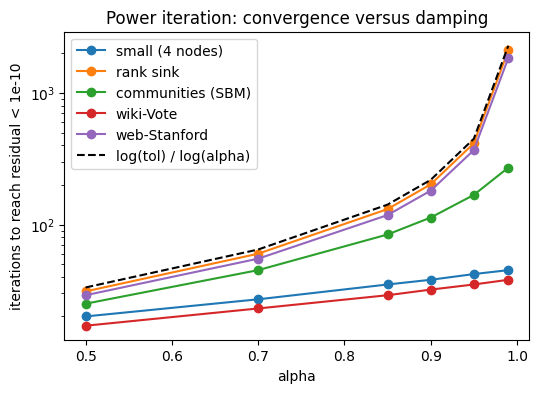

In [20]:
# Plot iterations versus alpha
fig, ax = plt.subplots(figsize=(6, 4))
for name in graphs:
    ax.plot(alphas, iterations[name], marker="o", label=name)
ax.plot(alphas, bound, "k--", label="log(tol) / log(alpha)")
ax.set_yscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("iterations to reach residual < 1e-10")
ax.set_title("Power iteration: convergence versus damping")
ax.legend()
save_fig(fig, "iterations_vs_alpha")
plt.show()

### 7.2 Second eigenvalue and predicted iteration counts (M4)
For $i \ge 2$, $\lambda_i(G) = \alpha\,\lambda_i(\bar P)$. With $\mu = |\lambda_2(\bar P)|$ the residual shrinks by about $\alpha\mu$
per step, so $k \approx \ln(\text{tol})/\ln(\alpha\mu)$. We compute $|\lambda_2(G)|$ once, at $\alpha = 0.85$, with ARPACK (`eigs`)
applied to the matrix-free operator, and test whether this single number predicts the counts of 7.1 for all $\alpha$.

*Note:* with its default tolerance (machine precision), `eigs` did not finish on web-Stanford after more than 8 minutes.
With `tol=1e-8` it finishes in seconds.

In [21]:
# Second eigenvalue of G with ARPACK (eigs), using the matrix-free product
def google_operator(P, dangling, alpha, v):
    """Wrap the matrix-free product G x as a LinearOperator, so scipy's eigs can use it."""
    n = P.shape[0]
    def matvec(x):
        return google_matvec(P, dangling, x, alpha, v)
    return spla.LinearOperator((n, n), matvec=matvec, dtype=float)

def second_eigenvalue_modulus(P, dangling, alpha):
    """Return |lambda_2(G)|, the second largest eigenvalue modulus of G."""
    n = P.shape[0]
    v = np.ones(n) / n
    G_op = google_operator(P, dangling, alpha, v)
    rng = np.random.default_rng(SEED)
    v0 = rng.random(n)                      # fixed starting vector, so ARPACK is reproducible
    eigenvalues = spla.eigs(G_op, k=2, which="LM", v0=v0, tol=1e-8, maxiter=300,
                           return_eigenvectors=False)
    moduli = np.sort(np.abs(eigenvalues))[::-1]
    return moduli[1]

# Check against the dense result of Section 2.3
lam2_small = second_eigenvalue_modulus(P_small, dangling_small, alpha)
print("|lambda_2| small graph, eigs :", lam2_small)
print("|lambda_2| small graph, dense:", lambda2_abs)
assert np.isclose(lam2_small, lambda2_abs)

|lambda_2| small graph, eigs : 0.5205165703414253
|lambda_2| small graph, dense: 0.5205165703414253


In [22]:
# mu = |lambda_2(P_bar)| for each graph, and predicted iteration counts for every alpha
mu = {}
for name, (P, dangling) in graphs.items():
    lam2 = second_eigenvalue_modulus(P, dangling, alpha)    # at alpha = 0.85
    mu[name] = lam2 / alpha                                 # |lambda_2(G)| = alpha * |lambda_2(P_bar)|

    predicted = []
    for a in alphas:
        predicted.append(np.log(tol) / np.log(a * mu[name]))

    print(f"{name}: |lambda_2(G)| = {lam2:.4f}, mu = {mu[name]:.4f}")
    print("   predicted:", np.round(predicted))
    print("   measured :", iterations[name])

small (4 nodes): |lambda_2(G)| = 0.5205, mu = 0.6124
   predicted: [19. 27. 35. 39. 43. 46.]
   measured : [20, 27, 35, 38, 42, 45]
rank sink: |lambda_2(G)| = 0.8500, mu = 1.0000
   predicted: [  33.   65.  142.  219.  449. 2291.]
   measured : [31, 60, 131, 202, 415, 2116]
communities (SBM): |lambda_2(G)| = 0.8030, mu = 0.9448
   predicted: [ 31.  56. 105. 142. 213. 344.]
   measured : [25, 45, 84, 113, 168, 271]
wiki-Vote: |lambda_2(G)| = 0.5014, mu = 0.5899
   predicted: [19. 26. 33. 36. 40. 43.]
   measured : [17, 23, 29, 32, 35, 38]
web-Stanford: |lambda_2(G)| = 0.8500, mu = 1.0000
   predicted: [  33.   65.  142.  219.  449. 2291.]
   measured : [29, 55, 118, 181, 368, 1848]


**Observation.** $\mu = 1$ for the rank sink and web-Stanford (closed groups of nodes), $\mu < 1$ for the small graph and wiki-Vote.
One value of $\mu$ predicts the iteration counts for every $\alpha$. The prediction is a slight overestimate, because the starting
vector $v$ has only a small component along the slow eigenvectors.

### 7.3 Comparison with library routines (M5)
Three solvers use the same matrix-free product:
- our **power iteration**;
- ARPACK **`eigs`**: Arnoldi applied to the eigenvalue problem $Gx = x$;
- **GMRES(30)**: Arnoldi applied to the linear system $(I - \alpha\bar P)x = (1-\alpha)v$.

Fair comparison: setup excluded, one BLAS thread, and the accuracy of every result is evaluated afterwards with the same
measure $\|Gx - x\|_1$. GMRES uses the sufficient 2-norm target $\text{tol}/\sqrt{n}$, since $\|r\|_1 \le \sqrt{n}\,\|r\|_2$.
The main measure of work is the number of matrix-vector products, which does not depend on the language or the machine.

In [23]:
# PageRank with eigs (ARPACK), counting the matrix-vector products
def pagerank_eigs(P, dangling, alpha, v, tol=1e-10):
    """PageRank as the dominant eigenvector of G, computed by ARPACK (Arnoldi).

    Returns x (normalized to sum 1) and the number of G x products used.
    """
    n = P.shape[0]
    counter = {"matvecs": 0}
    def matvec(x):
        counter["matvecs"] += 1
        return google_matvec(P, dangling, x, alpha, v)
    G_op = spla.LinearOperator((n, n), matvec=matvec, dtype=float)
    rng = np.random.default_rng(SEED)
    v0 = rng.random(n)                      # fixed starting vector, so ARPACK is reproducible
    eigenvalues, eigenvectors = spla.eigs(G_op, k=1, which="LM", v0=v0, tol=tol, maxiter=300)
    x = np.real(eigenvectors[:, 0])
    x = x / x.sum()                         # normalize to sum 1 (also fixes the sign)
    return x, counter["matvecs"]

# Check against the dense reference of Section 2.3
x_eigs_small, matvecs_small = pagerank_eigs(P_small, dangling_small, alpha, v_small)
print("eigs PageRank, small graph:", x_eigs_small)
print("Matvecs used              :", matvecs_small)
assert np.allclose(x_eigs_small, x_ref)

eigs PageRank, small graph: [0.233994 0.186671 0.345341 0.233994]
Matvecs used              : 6


In [24]:
# PageRank with GMRES on the linear system (I - alpha * P_bar) x = (1 - alpha) v
def pagerank_gmres(P, dangling, alpha, v, tol=1e-10, restart=30):
    """PageRank as the solution of (I - alpha * P_bar) x = (1 - alpha) v, computed by GMRES.

    Returns x (normalized to sum 1) and the number of A z products used.
    """
    n = P.shape[0]
    counter = {"matvecs": 0}
    def matvec(z):
        counter["matvecs"] += 1
        z = np.asarray(z).reshape(-1)                  # some SciPy versions pass an (n, 1) array
        P_bar_z = P @ z + v * z[dangling].sum()        # same dangling fix as google_matvec
        return z - alpha * P_bar_z
    A = spla.LinearOperator((n, n), matvec=matvec, dtype=float)
    b = (1 - alpha) * v
    # ||r||_1 <= sqrt(n) ||r||_2, so this 2-norm target guarantees ||r||_1 <= tol (lecture slide 18)
    x, info = spla.gmres(A, b, x0=v.copy(), restart=restart, maxiter=1000,
                         rtol=0.0, atol=tol / np.sqrt(n))
    assert info == 0                                   # GMRES converged
    x = x / x.sum()
    return x, counter["matvecs"]

# Check against the dense reference of Section 2.3
x_gmres_small, matvecs_gmres_small = pagerank_gmres(P_small, dangling_small, alpha, v_small)
print("GMRES PageRank, small graph:", x_gmres_small)
assert np.allclose(x_gmres_small, x_ref)

GMRES PageRank, small graph: [0.233994 0.186671 0.345341 0.233994]


In [25]:
# Power iteration versus eigs (ARPACK) versus GMRES: matvecs, time, memory, accuracy
cases = [("wiki-Vote", 0.85, 3), ("web-Stanford", 0.85, 3), ("web-Stanford", 0.99, 1)]   # (graph, alpha, repeats)
solvers = ["power iteration", "eigs (ARPACK)", "GMRES(30)"]

def run_solver(solver, P, dangling, a, v):
    """Run one solver and return (x, number of matrix-vector products)."""
    if solver == "power iteration":
        x, residuals = power_iteration(P, dangling, a, v, tol=1e-10, max_iter=10000)
        return x, len(residuals)
    if solver == "eigs (ARPACK)":
        return pagerank_eigs(P, dangling, a, v, tol=1e-10)
    return pagerank_gmres(P, dangling, a, v, tol=1e-10)

for name, a, n_repeats in cases:
    P, dangling = graphs[name]
    n = P.shape[0]
    v = np.ones(n) / n
    print(name, "alpha =", a)
    print("  solver            matvecs   time (s)   memory (MB)   ||Gx - x||_1   ||x - x_power||_1   positive")

    for solver in solvers:
        # Runtime: best of n_repeats runs
        times = []
        for repeat in range(n_repeats):
            t_start = time.perf_counter()
            x, matvecs = run_solver(solver, P, dangling, a, v)
            times.append(time.perf_counter() - t_start)

        # Peak extra memory (separate run, since tracemalloc slows the code down)
        tracemalloc.start()
        run_solver(solver, P, dangling, a, v)
        peak = tracemalloc.get_traced_memory()[1] / 1e6
        tracemalloc.stop()

        if solver == "power iteration":
            x_power = x
        residual = np.linalg.norm(google_matvec(P, dangling, x, a, v) - x, 1)
        difference = np.linalg.norm(x - x_power, 1)
        print(f"  {solver:16s}  {matvecs:7d}   {min(times):8.3f}   {peak:11.1f}   {residual:12.2e}"
              f"   {difference:17.2e}   {np.all(x > 0)}")
    print()

wiki-Vote alpha = 0.85
  solver            matvecs   time (s)   memory (MB)   ||Gx - x||_1   ||x - x_power||_1   positive
  power iteration        29      0.015           0.3       9.08e-11            0.00e+00   True
  eigs (ARPACK)          21      0.014           2.6       2.69e-11            1.80e-10   True
  GMRES(30)              22      0.020           2.2       1.77e-11            1.75e-10   True

web-Stanford alpha = 0.85
  solver            matvecs   time (s)   memory (MB)   ||Gx - x||_1   ||x - x_power||_1   positive
  power iteration       118      2.352           9.0       9.89e-11            0.00e+00   True
  eigs (ARPACK)          96      1.827         101.5       5.67e-11            2.69e-10   True
  GMRES(30)              92      1.906          88.0       5.47e-12            1.31e-10   True

web-Stanford alpha = 0.99
  solver            matvecs   time (s)   memory (MB)   ||Gx - x||_1   ||x - x_power||_1   positive
  power iteration      1848     24.345           9.1    

**Observation.** All three solvers reach the same vector (differences of order $10^{-10}$), and GMRES even reaches a smaller
residual because of its stricter 2-norm target.
- At $\alpha = 0.85$ the three methods need a similar number of matrix-vector products.
- At $\alpha = 0.99$ on web-Stanford, GMRES needs about 4 times fewer products than power iteration and is the fastest,
  while `eigs` needs more products than power iteration and is the slowest. Both use Arnoldi: the difference is the
  formulation. A likely explanation is that `eigs` must separate $\lambda_1 = 1$ from many eigenvalues of modulus close to
  $\alpha = 0.99$, while GMRES builds the solution of the linear system directly from the Krylov space (hypothesis, not tested).
- Memory: the Krylov methods store 20 to 30 vectors of length $n$, about 10 times the extra memory of power iteration,
  and more than $P$ itself on web-Stanford.

### 7.4 Scaling experiment
Subgraphs formed by the first $k$ nodes of web-Stanford, $k$ from 10,000 to 281,903. $P$ is rebuilt for every subgraph,
because out-degrees change. Expected: time per matvec $\propto \text{nnz}$, memory of $P \propto \text{nnz}$, extra memory of
power iteration $\propto n$, and an iteration count independent of $n$.
*Limitation:* the structure of the subgraphs also changes with $k$.

In [26]:
# Scaling experiment on subgraphs of web-Stanford (first k nodes)
n_web, edges_web = load_snap_graph(download_snap("web-Stanford"))
sizes = [10000, 20000, 40000, 80000, 160000, n_web]
scaling = {"n": [], "nnz": [], "time_per_matvec_ms": [], "memory_P_mb": [], "peak_pi_mb": []}

for k in sizes:
    # Keep only the edges between the first k nodes, then rebuild P (out-degrees change)
    edges_sub = []
    for source, target in edges_web:
        if source < k and target < k:
            edges_sub.append((source, target))
    P, dangling = build_transition_matrix(k, edges_sub)
    v = np.ones(k) / k

    # Runtime: best of 3 runs
    times = []
    for repeat in range(3):
        t_start = time.perf_counter()
        x, residuals = power_iteration(P, dangling, alpha, v)
        times.append(time.perf_counter() - t_start)

    # Peak extra memory of power iteration
    tracemalloc.start()
    power_iteration(P, dangling, alpha, v)
    peak_pi = tracemalloc.get_traced_memory()[1] / 1e6
    tracemalloc.stop()

    ms_per_matvec = 1000 * min(times) / len(residuals)
    memory_P = (P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 1e6
    scaling["n"].append(k)
    scaling["nnz"].append(P.nnz)
    scaling["time_per_matvec_ms"].append(ms_per_matvec)
    scaling["memory_P_mb"].append(memory_P)
    scaling["peak_pi_mb"].append(peak_pi)

    print(f"n = {k:6d}  nnz = {P.nnz:7d}  iterations = {len(residuals):3d}  "
          f"time/matvec = {ms_per_matvec:.3f} ms  P = {memory_P:.2f} MB  extra = {peak_pi:.2f} MB")

n =  10000  nnz =   95676  iterations = 121  time/matvec = 0.374 ms  P = 1.19 MB  extra = 0.40 MB
n =  20000  nnz =  224390  iterations = 124  time/matvec = 0.785 ms  P = 2.77 MB  extra = 0.80 MB
n =  40000  nnz =  414827  iterations = 123  time/matvec = 1.428 ms  P = 5.14 MB  extra = 1.29 MB
n =  80000  nnz =  794169  iterations = 122  time/matvec = 2.767 ms  P = 9.85 MB  extra = 2.57 MB
n = 160000  nnz = 1504126  iterations = 121  time/matvec = 5.442 ms  P = 18.69 MB  extra = 5.13 MB
n = 281903  nnz = 2312497  iterations = 118  time/matvec = 10.722 ms  P = 28.88 MB  extra = 9.03 MB


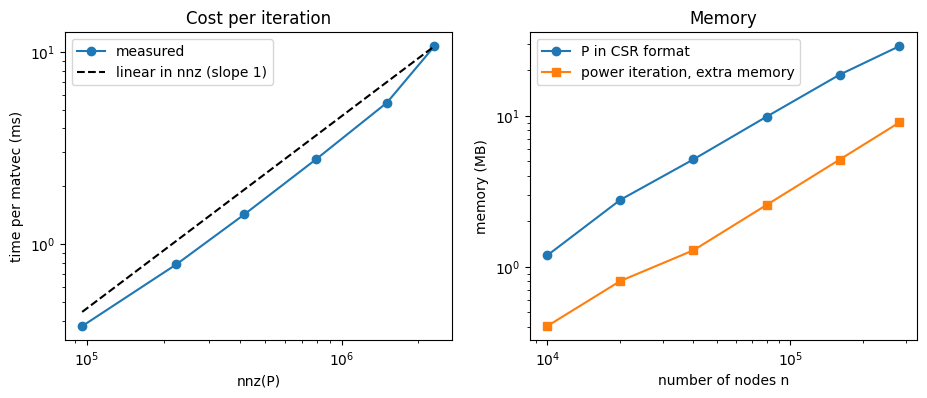

In [27]:
# Plot the scaling results
nnz = np.array(scaling["nnz"])
time_per_matvec = np.array(scaling["time_per_matvec_ms"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].loglog(nnz, time_per_matvec, marker="o", label="measured")
axes[0].loglog(nnz, time_per_matvec[-1] * nnz / nnz[-1], "k--", label="linear in nnz (slope 1)")
axes[0].set_xlabel("nnz(P)")
axes[0].set_ylabel("time per matvec (ms)")
axes[0].set_title("Cost per iteration")
axes[0].legend()

axes[1].loglog(scaling["n"], scaling["memory_P_mb"], marker="o", label="P in CSR format")
axes[1].loglog(scaling["n"], scaling["peak_pi_mb"], marker="s", label="power iteration, extra memory")
axes[1].set_xlabel("number of nodes n")
axes[1].set_ylabel("memory (MB)")
axes[1].set_title("Memory")
axes[1].legend()

save_fig(fig, "scaling_web_stanford")
plt.show()

**Observation.** Time per matvec grows linearly with nnz (log-log slope close to 1; deviations are at the level of timing noise).
The extra memory of power iteration is exactly four vectors of length $n$. The iteration count barely changes:
size does not determine convergence, structure does.

### 7.5 Residual versus stability of the ordering
The residual measures the whole vector; the ranking depends on the gaps between entries. If $\|x - x^*\|_1 \le b$, every entry
is off by at most $b$, so the order of two nodes is certified only if their gap exceeds $2b$.
First, a perturbation of $v$ of size $10^{-8}$ swaps the exactly tied nodes 0 and 3 of the small graph.
Then we count how many consecutive pairs of the real rankings are certified by the computed accuracy.

In [28]:
# A near tie. A tiny perturbation of v swaps the order of nodes 0 and 3
eps = 1e-8
shift = np.array([1.0, 0.0, 0.0, -1.0])     # move eps of teleportation from node 3 to node 0 (sum stays 1)

x_plus, _ = power_iteration(P_small, dangling_small, alpha, v_small + eps * shift)
x_minus, _ = power_iteration(P_small, dangling_small, alpha, v_small - eps * shift)

tau, p_value = scipy.stats.kendalltau(x_plus, x_minus)
rho, p_value = scipy.stats.spearmanr(x_plus, x_minus)

print("||x_plus - x_minus||_1 :", np.linalg.norm(x_plus - x_minus, 1))
print("Node 0 above node 3?   : plus", x_plus[0] > x_plus[3], "| minus", x_minus[0] > x_minus[3])
print("Kendall tau            :", tau)
print("Spearman rho           :", rho)

||x_plus - x_minus||_1 : 1.6170158545492086e-08
Node 0 above node 3?   : plus True | minus False
Kendall tau            : 0.6666666666666669
Spearman rho           : 0.7999999999999999


In [29]:
# Which part of the ranking is certified by the computed accuracy?
for name in ["wiki-Vote", "web-Stanford"]:
    P = real_graphs[name]["P"]
    dangling = real_graphs[name]["dangling"]
    x = real_graphs[name]["x"]                   # computed in 6.3 with alpha = 0.85, tol = 1e-10
    n = real_graphs[name]["n"]
    v = np.ones(n) / n

    residual = np.linalg.norm(google_matvec(P, dangling, x, alpha, v) - x, 1)
    error_bound = residual / (1 - alpha)         # ||x - x*||_1 <= error_bound (Section 5)

    x_sorted = np.sort(x)[::-1]                  # PageRank values from largest to smallest
    gaps = x_sorted[:-1] - x_sorted[1:]          # gap between consecutive nodes in the ranking

    print(f"{name}: residual = {residual:.2e}, error bound b = {error_bound:.2e}, typical value 1/n = {1 / n:.2e}")
    print(f"   exact ties (gap = 0): {np.sum(gaps == 0)} of {n - 1} consecutive pairs")
    print(f"   order not certified (gap < 2b): {np.sum(gaps < 2 * error_bound)}, "
          f"among the top 100: {np.sum(gaps[:99] < 2 * error_bound)}")

wiki-Vote: residual = 9.08e-11, error bound b = 6.06e-10, typical value 1/n = 1.41e-04
   exact ties (gap = 0): 4762 of 7114 consecutive pairs
   order not certified (gap < 2b): 4774, among the top 100: 0
web-Stanford: residual = 9.89e-11, error bound b = 6.60e-10, typical value 1/n = 3.55e-06
   exact ties (gap = 0): 134829 of 281902 consecutive pairs
   order not certified (gap < 2b): 274771, among the top 100: 9


**Observation.** The top of the wiki-Vote ranking is fully certified. Most of the tail of both rankings consists of exact ties
(structurally identical nodes, e.g. wiki-Vote users who received no votes) and near ties, whose order is decided by
round-off and not by the graph. On web-Stanford a few pairs inside the top 100 are exact ties (next cell).

*Investigation of the exact ties in the top 100 of web-Stanford.* For every tied pair we check whether the two nodes
receive links from exactly the same nodes (apart from each other).

In [30]:
# Exact ties in the top 100 of web-Stanford: do the tied nodes have the same in-links?
x = real_graphs["web-Stanford"]["x"]
P = real_graphs["web-Stanford"]["P"]
top = np.argsort(-x, kind="stable")[:100]       # 100 largest values; exact ties keep the index order
for i in range(99):
    node1, node2 = top[i], top[i + 1]
    if x[node1] == x[node2]:
        # Row i of P lists the nodes that link to i (P[i, j] != 0 for an edge j -> i)
        same_in_links = set(P[node1].indices) - {node2} == set(P[node2].indices) - {node1}
        print(f"ranks {i + 1}-{i + 2}: nodes {node1} and {node2}, {P[node1].nnz} in-links each, "
              f"same in-links apart from each other: {same_in_links}")

ranks 15-16: nodes 446 and 447, 4906 in-links each, same in-links apart from each other: True
ranks 44-45: nodes 1521 and 1523, 8346 in-links each, same in-links apart from each other: True
ranks 47-48: nodes 1498 and 1504, 8346 in-links each, same in-links apart from each other: True
ranks 48-49: nodes 1504 and 1510, 8346 in-links each, same in-links apart from each other: True
ranks 49-50: nodes 1510 and 1513, 8346 in-links each, same in-links apart from each other: True
ranks 50-51: nodes 1513 and 1516, 8346 in-links each, same in-links apart from each other: True
ranks 51-52: nodes 1516 and 1520, 8346 in-links each, same in-links apart from each other: True
ranks 54-55: nodes 1500 and 1507, 8346 in-links each, same in-links apart from each other: True


**Observation.** The tied nodes belong to densely interlinked groups (probably pages sharing a common template) and receive
links from the same nodes, so PageRank cannot distinguish them: their relative order is arbitrary.

### 7.6 Edge perturbation (M6)
Each edge is removed independently with probability 0.1%, 1% or 5% (same seed, so the removed sets are nested).
PageRank is recomputed for $\alpha \in \{0.5, 0.85, 0.99\}$ and compared with the original using $\|x - x'\|_1$,
Kendall $\tau$, Spearman $\rho$ and the overlap of the top-100 lists.
Theory: with $U$ the set of nodes that lost an out-link, $\|x - x'\|_1 \le \frac{2\alpha}{1-\alpha}\sum_{j \in U} x_j$.
*Limitation:* one random realization per fraction.

In [31]:
# Random edge removal
def remove_random_edges(edges, fraction, seed):
    """Remove each edge independently with probability `fraction`.

    Returns the kept edges and the set U of nodes that lost at least one out-link.
    With the same seed, the edges removed for a small fraction are a subset of those
    removed for a larger fraction, so the experiments are nested.
    """
    rng = np.random.default_rng(seed)
    kept_edges = []
    changed_sources = set()
    for source, target in edges:
        if rng.random() < fraction:
            changed_sources.add(source)
        else:
            kept_edges.append((source, target))
    return kept_edges, changed_sources

In [32]:
# Edge perturbation experiment
n_wiki, edges_wiki = load_snap_graph(download_snap("wiki-Vote"))
datasets = [("wiki-Vote", n_wiki, edges_wiki), ("web-Stanford", n_web, edges_web)]
alphas_pert = [0.5, 0.85, 0.99]
fractions = [0.001, 0.01, 0.05]
top_k = 100
perturbation_results = {}            # (graph, alpha) -> one list per measure, one value per fraction

for name, n, edges in datasets:
    P, dangling = graphs[name]
    v = np.ones(n) / n

    # Unperturbed PageRank for each alpha
    x_original = {}
    for a in alphas_pert:
        x_original[a], _ = power_iteration(P, dangling, a, v, max_iter=10000)
        perturbation_results[(name, a)] = {"change": [], "tau": [], "overlap": []}

    for fraction in fractions:
        kept_edges, changed_sources = remove_random_edges(edges, fraction, SEED)
        P_new, dangling_new = build_transition_matrix(n, kept_edges)
        print(f"{name}: removed {len(edges) - len(kept_edges)} edges ({100 * fraction:g}%)")

        for a in alphas_pert:
            x = x_original[a]
            x_new, _ = power_iteration(P_new, dangling_new, a, v, max_iter=10000)

            change = np.linalg.norm(x_new - x, 1)
            bound = 2 * a / (1 - a) * x[list(changed_sources)].sum()
            tau, _ = scipy.stats.kendalltau(x, x_new)
            rho, _ = scipy.stats.spearmanr(x, x_new)
            top_old = set(np.argsort(-x, kind="stable")[:top_k])        # stable: exact ties keep index order
            top_new = set(np.argsort(-x_new, kind="stable")[:top_k])
            overlap = len(top_old & top_new)

            results = perturbation_results[(name, a)]
            results["change"].append(change)
            results["tau"].append(tau)
            results["overlap"].append(overlap)
            print(f"   alpha = {a:4.2f}   ||x - x'||_1 = {change:.2e} (bound {bound:.2e})   "
                  f"tau = {tau:.4f}   rho = {rho:.4f}   top-{top_k} overlap = {overlap}")
    print()

wiki-Vote: removed 108 edges (0.1%)
   alpha = 0.50   ||x - x'||_1 = 6.50e-04 (bound 4.64e-02)   tau = 0.9998   rho = 1.0000   top-100 overlap = 100
   alpha = 0.85   ||x - x'||_1 = 1.14e-03 (bound 3.36e-01)   tau = 0.9997   rho = 1.0000   top-100 overlap = 99
   alpha = 0.99   ||x - x'||_1 = 1.37e-03 (bound 6.37e+00)   tau = 0.9997   rho = 1.0000   top-100 overlap = 100
wiki-Vote: removed 1095 edges (1%)
   alpha = 0.50   ||x - x'||_1 = 6.19e-03 (bound 2.97e-01)   tau = 0.9975   rho = 0.9998   top-100 overlap = 98
   alpha = 0.85   ||x - x'||_1 = 9.70e-03 (bound 2.06e+00)   tau = 0.9974   rho = 0.9998   top-100 overlap = 98
   alpha = 0.99   ||x - x'||_1 = 1.11e-02 (bound 3.86e+01)   tau = 0.9974   rho = 0.9998   top-100 overlap = 98
wiki-Vote: removed 5209 edges (5%)
   alpha = 0.50   ||x - x'||_1 = 2.22e-02 (bound 6.53e-01)   tau = 0.9911   rho = 0.9992   top-100 overlap = 97
   alpha = 0.85   ||x - x'||_1 = 3.64e-02 (bound 4.29e+00)   tau = 0.9911   rho = 0.9993   top-100 overlap =

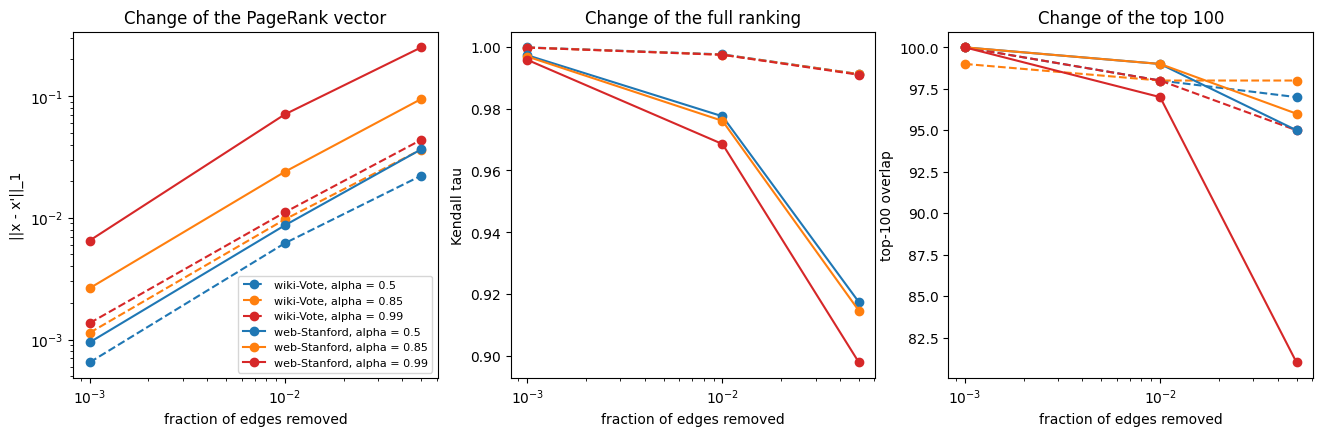

In [33]:
# Plot the perturbation results (colour = alpha, line style = graph)
colors = {0.5: "tab:blue", 0.85: "tab:orange", 0.99: "tab:red"}
styles = {"web-Stanford": "-", "wiki-Vote": "--"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for (name, a), results in perturbation_results.items():
    label = f"{name}, alpha = {a}"
    axes[0].loglog(fractions, results["change"], styles[name], color=colors[a], marker="o", label=label)
    axes[1].semilogx(fractions, results["tau"], styles[name], color=colors[a], marker="o")
    axes[2].semilogx(fractions, results["overlap"], styles[name], color=colors[a], marker="o")

axes[0].set_title("Change of the PageRank vector")
axes[1].set_title("Change of the full ranking")
axes[2].set_title("Change of the top 100")
axes[0].set_ylabel("||x - x'||_1")
axes[1].set_ylabel("Kendall tau")
axes[2].set_ylabel("top-100 overlap")
for ax in axes:
    ax.set_xlabel("fraction of edges removed")
axes[0].legend(fontsize=8)
save_fig(fig, "perturbation_edges")
plt.show()

**Observation.** The change of $x$ is roughly linear in the fraction of removed edges and several orders of magnitude larger
than the numerical error: the accuracy of the ranking is limited by the data, not by the solver tolerance.
Sensitivity grows with $\alpha$ on web-Stanford but hardly on wiki-Vote (the three wiki-Vote curves overlap).
The head of the ranking is stable; Kendall $\tau$ drops mainly because of reshuffling among near ties in the tail.

### 7.7 Extension: warm start after a small graph modification
After removing a small fraction of edges, we recompute PageRank starting from $v$ (cold) and from the old PageRank vector (warm).
Since the residual decreases by about $\alpha\mu$ per step, the number of iterations is about
$k \approx \ln(\text{tol}/r_0)/\ln(\alpha\mu)$, where $r_0$ is the first residual. A warm start only reduces $r_0$,
and the factor $1/\ln(\alpha\mu)$ cancels in the relative saving:
$$\text{saving} \approx \frac{\ln(r_0^{\text{cold}}/r_0^{\text{warm}})}{\ln(r_0^{\text{cold}}/\text{tol})}.$$

In [34]:
# Warm start versus cold start after removing a small fraction of edges
fractions_update = [0.0001, 0.001, 0.01]
alphas_update = [0.85, 0.99]

for name, n, edges in datasets:
    P, dangling = graphs[name]
    v = np.ones(n) / n

    # PageRank of the original graph, for each alpha
    x_old = {}
    for a in alphas_update:
        x_old[a], _ = power_iteration(P, dangling, a, v, max_iter=10000)

    for fraction in fractions_update:
        kept_edges, _ = remove_random_edges(edges, fraction, SEED)
        P_new, dangling_new = build_transition_matrix(n, kept_edges)
        print(f"{name}: removed {len(edges) - len(kept_edges)} edges ({100 * fraction:g}%)")

        for a in alphas_update:
            x_cold, residuals_cold = power_iteration(P_new, dangling_new, a, v, max_iter=10000)
            x_warm, residuals_warm = power_iteration(P_new, dangling_new, a, v, max_iter=10000, x0=x_old[a])

            saving = 100 * (1 - len(residuals_warm) / len(residuals_cold))
            predicted = 100 * np.log(residuals_cold[0] / residuals_warm[0]) / np.log(residuals_cold[0] / tol)
            print(f"   alpha = {a:4.2f}   cold: {len(residuals_cold):4d} it   warm: {len(residuals_warm):4d} it   "
                  f"saving = {saving:4.1f}% (predicted {predicted:4.1f}%)   "
                  f"||x_cold - x_warm||_1 = {np.linalg.norm(x_cold - x_warm, 1):.1e}")
    print()

wiki-Vote: removed 12 edges (0.01%)
   alpha = 0.85   cold:   29 it   warm:   19 it   saving = 34.5% (predicted 40.4%)   ||x_cold - x_warm||_1 = 7.1e-11
   alpha = 0.99   cold:   38 it   warm:   24 it   saving = 36.8% (predicted 39.9%)   ||x_cold - x_warm||_1 = 4.3e-11
wiki-Vote: removed 108 edges (0.1%)
   alpha = 0.85   cold:   29 it   warm:   20 it   saving = 31.0% (predicted 30.4%)   ||x_cold - x_warm||_1 = 4.1e-11
   alpha = 0.99   cold:   38 it   warm:   26 it   saving = 31.6% (predicted 30.4%)   ||x_cold - x_warm||_1 = 6.8e-11
wiki-Vote: removed 1095 edges (1%)
   alpha = 0.85   cold:   29 it   warm:   24 it   saving = 17.2% (predicted 20.7%)   ||x_cold - x_warm||_1 = 6.2e-11
   alpha = 0.99   cold:   38 it   warm:   30 it   saving = 21.1% (predicted 20.8%)   ||x_cold - x_warm||_1 = 5.7e-11

web-Stanford: removed 228 edges (0.01%)
   alpha = 0.85   cold:  118 it   warm:   73 it   saving = 38.1% (predicted 37.2%)   ||x_cold - x_warm||_1 = 5.3e-10
   alpha = 0.99   cold: 1848 it  

**Observation.** Warm and cold start give the same vector (differences at the level of the tolerance). The relative saving
follows the predicted value, which depends only on the first residuals and not on $\alpha$ or on the graph.
The absolute saving is large only when convergence is slow (web-Stanford, $\alpha = 0.99$).

## 8. Summary

**Convergence.** The number of power iterations is $k \approx \ln(\text{tol})/\ln(\alpha\mu)$ with $\mu = |\lambda_2(\bar P)|$:
damping and graph structure enter as a product. Graphs with closed groups of nodes (rank sink, web-Stanford) have $\mu = 1$,
so $\alpha$ alone sets the speed and $\alpha \to 1$ is expensive. When $\mu < 1$ (wiki-Vote), $\alpha$ hardly matters.
Graph size does not change the iteration count (7.4).

**Cost.** One iteration costs $O(\text{nnz})$ time and power iteration needs $O(n)$ extra memory. GMRES needs far fewer
matrix-vector products for $\alpha$ close to 1, at about 10 times the memory; `eigs` brings no advantage on this problem.

**Stability.** A small residual guarantees an accurate vector, but only certifies the order of nodes whose scores differ by
more than twice the error bound. The head of the ranking is certified and stable; the tail is full of exact and near ties.
Under edge perturbations the vector changes roughly linearly, much more than the numerical error, and the sensitivity grows
with $\alpha$ by an amount that again depends on the graph structure.

**Limitations.** One random realization per perturbation level; scaling subgraphs also change structure;
the graph construction uses Python loops (setup time is reported separately).